# COGS 109 Checkpoint 1 | Member 3: Combined model
**Group question:** Does adding NCAA stats improve prediction of NBA points per game (first 3 post-combine seasons) beyond NBA Draft Combine measurements?

**My model (Member 3):** NCAA PPG + NCAA FG% + wingspan + max vertical + position (baseline Guard).
Member 1 uses combine only, Member 2 uses NCAA only, so my predictor set is different.

Run from the project folder (needs `data/` from `00_build_dataset.ipynb`).

## Step 1: Load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

features = pd.read_csv('data/predraft_features.csv')
outcomes = pd.read_csv('data/nba_outcomes.csv')

# join predictors to the outcome, keep only players matched to NCAA stats
df = features.merge(outcomes[['player_id', 'ppg_3yr']], on='player_id')
df = df[df.ncaa_match_status == 'matched'].reset_index(drop=True)
print('n =', len(df))
print('Position counts:')
print(df.position_group.value_counts())

n = 770
Position counts:
position_group
Guard      359
Forward    339
Center      72
Name: count, dtype: int64


## Step 2: Explore the data (Slides 1 and 2)
- n = 770 players. My model has p = 5 predictors: 4 quantitative (`ncaa_ppg`, `ncaa_fg_pct`, `wingspan_in`, `vertical_max_in`) and 1 qualitative (`position_group`, 3 levels, so 2 dummies).
- Outcome: `ppg_3yr`, NBA points per game (PPG).

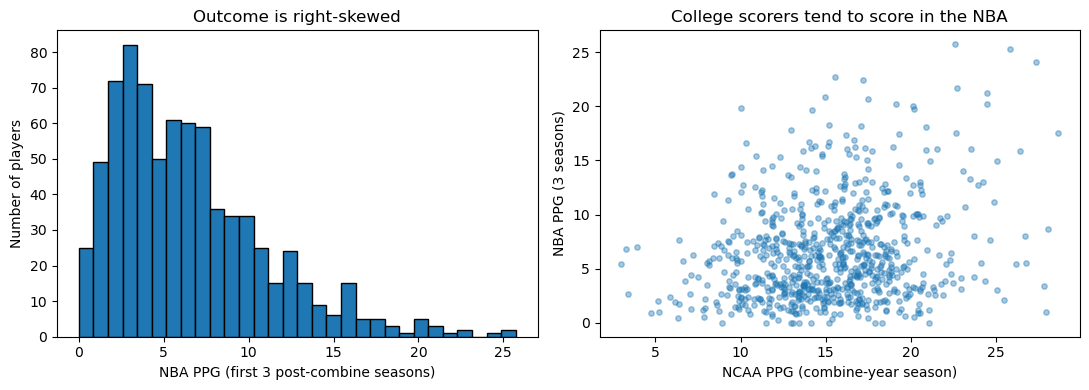

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))

axs[0].hist(df.ppg_3yr, bins=30, edgecolor='black')
axs[0].set(xlabel='NBA PPG (first 3 post-combine seasons)', ylabel='Number of players',
           title='Outcome is right-skewed')

axs[1].scatter(df.ncaa_ppg, df.ppg_3yr, alpha=.4, s=15)
axs[1].set(xlabel='NCAA PPG (combine-year season)', ylabel='NBA PPG (3 seasons)',
           title='College scorers tend to score in the NBA')
plt.tight_layout()
plt.show()

## Step 3: One shared train/test split
80% train / 20% test, `random_state=42`, stratified by position. This is the same split every group member uses (616 train / 154 test).

In [3]:
train_idx, test_idx = train_test_split(df.index, test_size=0.20, random_state=42,
                                       stratify=df.position_group)
train = df.loc[train_idx].copy()
test = df.loc[test_idx].copy()
print('Train:', len(train), '| Test:', len(test))

# fill missing predictor values with the TRAIN median (never look at test)
predictors = ['ncaa_ppg', 'ncaa_fg_pct', 'wingspan_in', 'vertical_max_in']
for col in predictors:
    median = train[col].median()
    train[col] = train[col].fillna(median)
    test[col] = test[col].fillna(median)

Train: 616 | Test: 154


## Step 4: Fit the model on the training set
$$\text{PPG} = \beta_0 + \beta_1\,\text{NCAA\_PPG} + \beta_2\,\text{NCAA\_FG\%} + \beta_3\,\text{Wingspan} + \beta_4\,\text{Vertical} + \beta_5\,\text{Pos}_{Forward} + \beta_6\,\text{Pos}_{Center} + \varepsilon$$
Baseline position: Guard (no term).

In [4]:
formula = ('ppg_3yr ~ ncaa_ppg + ncaa_fg_pct + wingspan_in + vertical_max_in'
           ' + C(position_group, Treatment(reference="Guard"))')
model = smf.ols(formula, data=train).fit()
print(model.summary().tables[1])
print('Train R-squared:', round(model.rsquared, 3))

                                                                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------------------
Intercept                                                     -8.0440      6.636     -1.212      0.226     -21.076       4.988
C(position_group, Treatment(reference="Guard"))[T.Center]     -0.5761      0.941     -0.612      0.540      -2.423       1.271
C(position_group, Treatment(reference="Guard"))[T.Forward]    -0.4479      0.541     -0.828      0.408      -1.511       0.615
ncaa_ppg                                                       0.2665      0.049      5.399      0.000       0.170       0.363
ncaa_fg_pct                                                    0.0656      0.034      1.925      0.055      -0.001       0.133
wingspan_in                                                    0.0459      0.073      0.631      0.528      -0.

### Fitted equation and interpretation
$$\widehat{\text{PPG}} = -8.04 + 0.267\,\text{NCAA\_PPG} + 0.066\,\text{NCAA\_FG\%} + 0.046\,\text{Wingspan} + 0.106\,\text{Vertical} - 0.448\,\text{Pos}_{Forward} - 0.576\,\text{Pos}_{Center}$$

- **Quantitative (`ncaa_ppg`):** holding FG%, wingspan, vertical and position fixed, each extra 1 point per game scored in college is associated with **0.267 more NBA points per game** (p < 0.001, the only clearly significant predictor).
- **Qualitative (Center vs Guard):** holding the other predictors fixed, Centers average **0.576 fewer NBA PPG** than Guards (the baseline), though this is not statistically significant (p = 0.54).

## Step 5: Check the 5 assumptions (training residuals)
### 5a. Linearity and 5b. Constant variance: residuals vs fitted

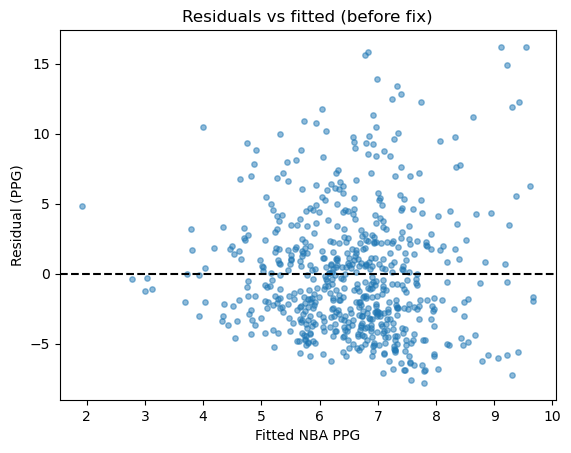

In [5]:
resid = model.resid
fitted = model.fittedvalues

plt.scatter(fitted, resid, alpha=.5, s=15)
plt.axhline(0, color='black', linestyle='--')
plt.xlabel('Fitted NBA PPG')
plt.ylabel('Residual (PPG)')
plt.title('Residuals vs fitted (before fix)')
plt.show()

**Read:** no strong curve, so linearity looks okay. But the spread grows to the right (mild funnel) and residuals are mostly positive at the extremes, so constant variance is **mildly violated**.

### 5c. Normal errors: Q-Q plot

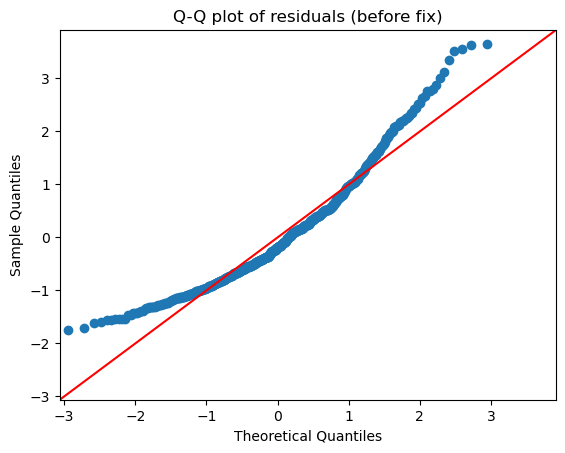

In [6]:
sm.qqplot(resid, line='45', fit=True)
plt.title('Q-Q plot of residuals (before fix)')
plt.show()

**Read:** the points bend up above the line on the right, so the residuals are right-skewed. Normality is **violated**.

### 5d. Independent errors
Each row is a different player and every player appears once, so there are no repeated measurements. Plot residuals by row order as a check.

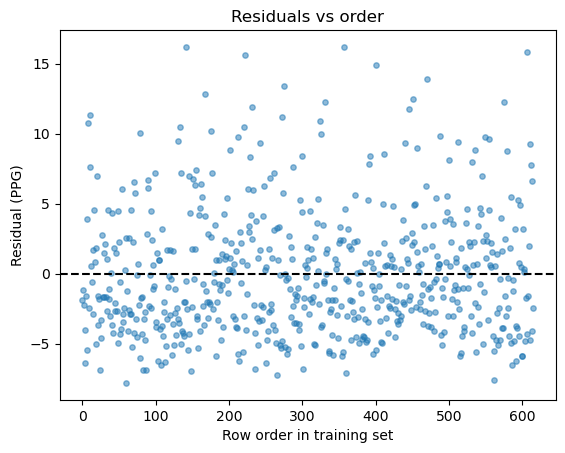

In [7]:
plt.scatter(range(len(resid)), resid, alpha=.5, s=15)
plt.axhline(0, color='black', linestyle='--')
plt.xlabel('Row order in training set')
plt.ylabel('Residual (PPG)')
plt.title('Residuals vs order')
plt.show()

**Read:** no runs or trends, so independence looks **satisfied** (players from the same draft class could be slightly related, but each player is a separate unit).

### 5e. No multicollinearity: correlation matrix and VIF

                 ncaa_ppg  ncaa_fg_pct  wingspan_in  vertical_max_in
ncaa_ppg             1.00        -0.11        -0.32             0.04
ncaa_fg_pct         -0.11         1.00         0.47            -0.18
wingspan_in         -0.32         0.47         1.00            -0.31
vertical_max_in      0.04        -0.18        -0.31             1.00


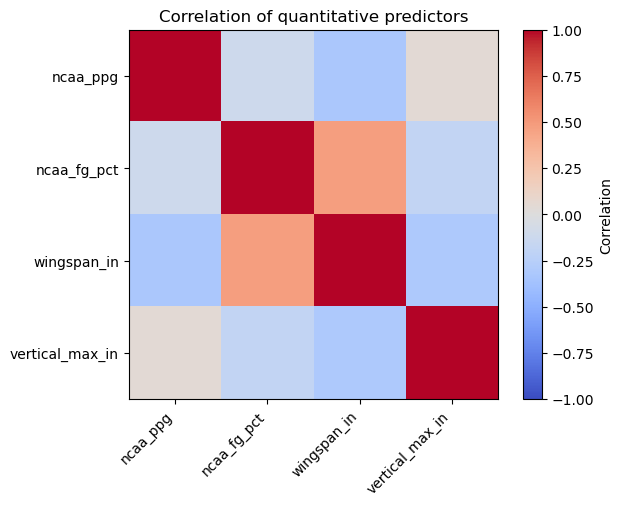

C(position_group, Treatment(reference="Guard"))[T.Center] 2.33
C(position_group, Treatment(reference="Guard"))[T.Forward] 2.22
ncaa_ppg 1.15
ncaa_fg_pct 1.5
wingspan_in 2.39
vertical_max_in 1.15


In [8]:
corr = train[predictors].corr()
print(corr.round(2))

plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.xticks(range(4), predictors, rotation=45, ha='right')
plt.yticks(range(4), predictors)
plt.colorbar(label='Correlation')
plt.title('Correlation of quantitative predictors')
plt.show()

# VIF for each predictor
X = pd.DataFrame(model.model.exog, columns=model.model.exog_names)
for i, name in enumerate(X.columns):
    if name != 'Intercept':
        print(name, round(variance_inflation_factor(X.values, i), 2))

**Read:** all VIFs are below 5 and no pair of predictors is strongly correlated, so multicollinearity is **satisfied**.

**Summary:** 3 of 5 assumptions fine (linearity, independence, multicollinearity). Constant variance (mild) and normality are violated, both from the right skew in NBA PPG, so I fix it by transforming the outcome.

## Step 6: Fix. Transform the outcome
A funnel plus right-skewed residuals suggests a log transform of the outcome. Some players have 0 PPG, so I use $\log(\text{PPG}+1)$.
Interpretation changes: a 1-unit increase in a predictor is associated with roughly a $100\cdot\beta$% change in (PPG+1).

                                                                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------------------
Intercept                                                      0.2224      0.927      0.240      0.810      -1.598       2.043
C(position_group, Treatment(reference="Guard"))[T.Center]     -0.0481      0.131     -0.366      0.715      -0.306       0.210
C(position_group, Treatment(reference="Guard"))[T.Forward]    -0.0365      0.076     -0.483      0.629      -0.185       0.112
ncaa_ppg                                                       0.0324      0.007      4.702      0.000       0.019       0.046
ncaa_fg_pct                                                    0.0071      0.005      1.496      0.135      -0.002       0.016
wingspan_in                                                    0.0039      0.010      0.384      0.701      -0.

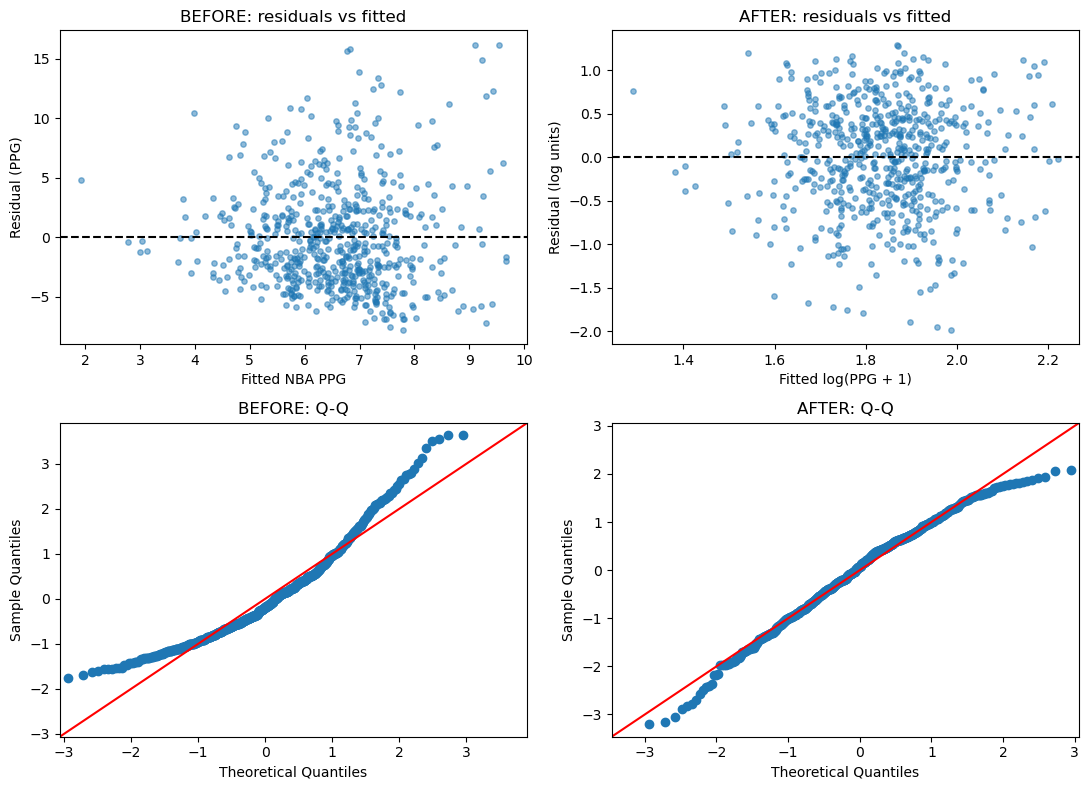

In [9]:
train['log_ppg'] = np.log(train.ppg_3yr + 1)
formula_log = formula.replace('ppg_3yr', 'log_ppg')
model_log = smf.ols(formula_log, data=train).fit()
print(model_log.summary().tables[1])

fig, axs = plt.subplots(2, 2, figsize=(11, 8))
axs[0, 0].scatter(fitted, resid, alpha=.5, s=15)
axs[0, 0].axhline(0, color='black', linestyle='--')
axs[0, 0].set(xlabel='Fitted NBA PPG', ylabel='Residual (PPG)', title='BEFORE: residuals vs fitted')

axs[0, 1].scatter(model_log.fittedvalues, model_log.resid, alpha=.5, s=15)
axs[0, 1].axhline(0, color='black', linestyle='--')
axs[0, 1].set(xlabel='Fitted log(PPG + 1)', ylabel='Residual (log units)', title='AFTER: residuals vs fitted')

sm.qqplot(resid, line='45', fit=True, ax=axs[1, 0])
axs[1, 0].set_title('BEFORE: Q-Q')
sm.qqplot(model_log.resid, line='45', fit=True, ax=axs[1, 1])
axs[1, 1].set_title('AFTER: Q-Q')
plt.tight_layout()
plt.show()

**Read:** after the log transform the funnel is gone and the Q-Q points follow the line much more closely (only a slight left tail remains), so the violations are fixed.

### Interpreting the log model in PPG
The log coefficients are percent-style effects, so to compare with the other members I convert to PPG: predict for a "typical" player (training-set average predictors), change one thing, and convert both predictions back with $e^{\hat y}-1$. The effect depends on the baseline player, so this is for a typical Guard.

In [10]:
# typical player = training means, Guard
typical = pd.DataFrame({c: [train[c].mean()] for c in predictors})
typical['position_group'] = 'Guard'

def ppg(player):
    return np.exp(model_log.predict(player)[0]) - 1

base = ppg(typical)
print('Typical Guard predicted NBA PPG:', round(base, 2))

# quantitative: +1 college PPG
more_scoring = typical.copy()
more_scoring['ncaa_ppg'] += 1
print('+1 NCAA PPG changes predicted NBA PPG by', round(ppg(more_scoring) - base, 2))

# qualitative: Center instead of Guard
center = typical.copy()
center['position_group'] = 'Center'
print('Center vs Guard changes predicted NBA PPG by', round(ppg(center) - base, 2))

Typical Guard predicted NBA PPG: 5.39
+1 NCAA PPG changes predicted NBA PPG by 0.21
Center vs Guard changes predicted NBA PPG by -0.3


## Step 7: Test both models once on the test set
For the log model, convert predictions back to PPG with $e^{\hat y} - 1$ so test MSE is on the same scale as the other members.

In [11]:
# original model
pred = model.predict(test)
mse = mean_squared_error(test.ppg_3yr, pred)
r2 = r2_score(test.ppg_3yr, pred)

# log model, back-transformed to PPG
pred_log = np.exp(model_log.predict(test)) - 1
mse_log = mean_squared_error(test.ppg_3yr, pred_log)
r2_log = r2_score(test.ppg_3yr, pred_log)

results = pd.DataFrame({'model': ['Original (PPG)', 'Log-transformed'],
                        'test_MSE': [mse, mse_log],
                        'test_R2': [r2, r2_log]})
print(results.round(3))

# teammates' results from the group files
print()
print(pd.read_csv('reports/group_comparison.csv')[['model', 'test_mse', 'test_r2']].round(3))

             model  test_MSE  test_R2
0   Original (PPG)    17.220    0.084
1  Log-transformed    18.654    0.008

      model  test_mse  test_r2
0  combined    17.220    0.084
1      ncaa    17.405    0.074
2   combine    17.978    0.044


## Step 8: Slide notes (Member 3)
**Results:** original model test MSE 17.22 PPG^2, R^2 0.084 (best of the three members; combine-only 17.98 / 0.044, NCAA-only 17.41 / 0.074). The log model cleaned up the residuals but test MSE rose to 18.65 and R^2 fell to 0.008 (back-transforming a log model tends to underpredict high scorers, and the original errors were mild).

- **Slide title idea:** "Right-skewed residuals were fixed by a log transform, but test error got worse".
- **Model slide:** equation and interpretations from Step 4, test MSE 17.22 and R^2 0.084.
- **Problem and fix slide:** the 2x2 before/after figure from Step 6.
- **Assumption line:** "Linearity, independence, multicollinearity (VIF < 2.4) held; mild non-constant variance and non-normal errors were fixed with log(PPG + 1)."
- **Which model to report as final:** the original model predicts better on the test set (lower MSE), so report it as the final model and the log model as the attempted fix. This also keeps `reports/combined_metrics.csv` consistent with the group comparison.
- **Comparison table row:** `ncaa_ppg, ncaa_fg_pct, wingspan, vertical, position`, MSE 17.22, R^2 0.084.